# Problema 5 — Segmentação de clientes com k-Means

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

## 1. Carregar e visualizar

,mean,median,std,min,max
Fresh,12000.297727,8504.0,12647.328865,3.0,112151.0
Milk,5796.265909,3627.0,7380.377175,55.0,73498.0
Grocery,7951.277273,4755.5,9503.162829,3.0,92780.0
Frozen,3071.931818,1526.0,4854.673333,25.0,60869.0
Detergents_Paper,2881.493182,816.5,4767.854448,3.0,40827.0
Delicassen,1524.870455,965.5,2820.105937,3.0,47943.0


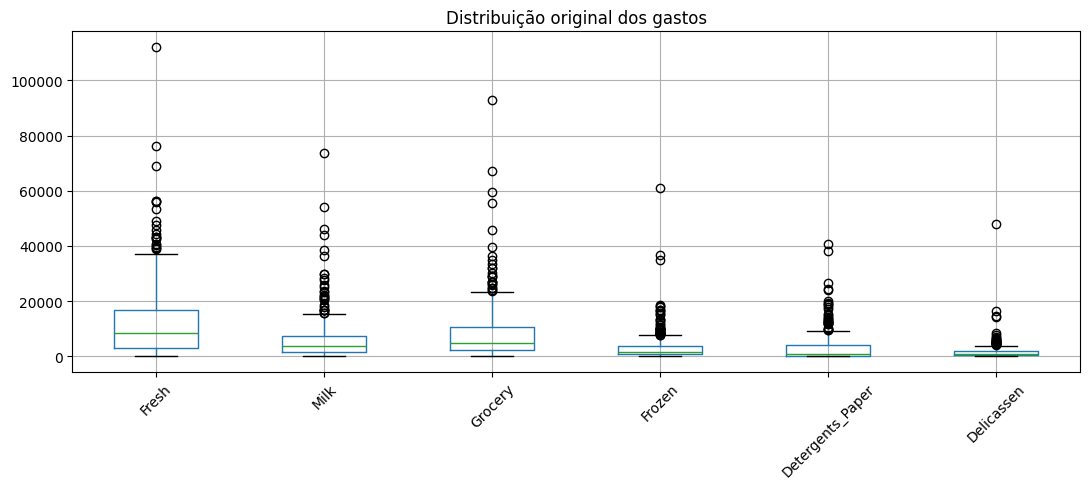

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"
df = pd.read_csv(url)

gastos = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
df = df.rename(columns={"Detergents_Paper": "Detergents_Paper"})
channel = df["Channel"].copy()
region = df["Region"].copy()
X_original = df[gastos].copy()

resumo = X_original.agg(["mean", "median", "std", "min", "max"]).T
display(resumo)

X_original.boxplot(figsize=(11, 5), rot=45)
plt.title("Distribuição original dos gastos")
plt.tight_layout()
plt.show()

## 2. Transformação logarítmica e padronização

In [ ]:
X_log = np.log1p(X_original)
escalador = StandardScaler()
X = escalador.fit_transform(X_log)

correlacao = X_original.corr()
display(correlacao)

print("Correlação Grocery–Detergents_Paper:",
      correlacao.loc["Grocery", "Detergents_Paper"])

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Fresh,1.000000,0.100510,-0.011854,0.345881,-0.101953,0.244690
Milk,0.100510,1.000000,0.728335,0.123994,0.661816,0.406368
Grocery,-0.011854,0.728335,1.000000,-0.040193,0.924641,0.205497
Frozen,0.345881,0.123994,-0.040193,1.000000,-0.131525,0.390947
Detergents_Paper,-0.101953,0.661816,0.924641,-0.131525,1.000000,0.069291
Delicassen,0.244690,0.406368,0.205497,0.390947,0.069291,1.000000


Correlação Grocery–Detergents_Paper: 0.9246406908542676


## 3. Escolher o número de grupos

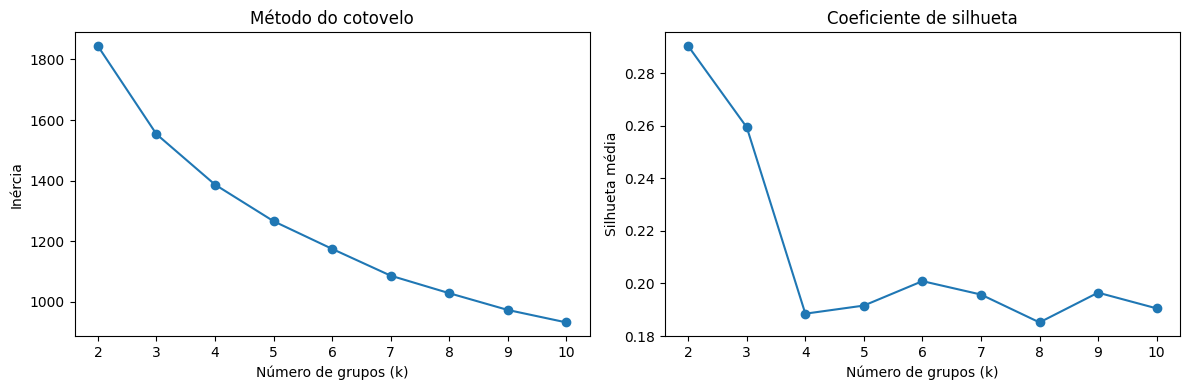

k com maior silhueta: 2
Escolha o k final considerando também o cotovelo e a utilidade comercial.


In [ ]:
valores_k = range(2, 11)
inercias = []
silhuetas = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    rotulos = modelo.fit_predict(X)
    inercias.append(modelo.inertia_)
    silhuetas.append(silhouette_score(X, rotulos))

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].plot(list(valores_k), inercias, marker="o")
eixos[0].set_title("Método do cotovelo")
eixos[0].set_xlabel("Número de grupos (k)")
eixos[0].set_ylabel("Inércia")
eixos[1].plot(list(valores_k), silhuetas, marker="o")
eixos[1].set_title("Coeficiente de silhueta")
eixos[1].set_xlabel("Número de grupos (k)")
eixos[1].set_ylabel("Silhueta média")
plt.tight_layout()
plt.show()

melhor_k = list(valores_k)[int(np.argmax(silhuetas))]
print("k com maior silhueta:", melhor_k)
print("Escolha o k final considerando também o cotovelo e a utilidade comercial.")

## 4. Comparar inicializações


In [ ]:
for inicializacao in ["random", "k-means++"]:
    inercias_execucoes = []
    for semente in range(10):
        modelo = KMeans(
            n_clusters=melhor_k, init=inicializacao, n_init=1, random_state=semente
        )
        modelo.fit(X)
        inercias_execucoes.append(modelo.inertia_)
    print(f"{inicializacao}:")
    print(np.round(inercias_execucoes, 2))
    print("Média:", round(np.mean(inercias_execucoes), 2),
          "| Desvio padrão:", round(np.std(inercias_execucoes), 2))

random:
[1844.06 1844.06 1844.06 1844.13 1844.06 1844.06 1844.13 1844.13 1844.06
 1844.06]
Média: 1844.08 | Desvio padrão: 0.03
k-means++:
[1844.13 1844.06 1844.06 1844.06 1844.13 1844.06 1844.13 1844.13 1844.06
 1844.06]
Média: 1844.09 | Desvio padrão: 0.03


## 5. Interpretar os grupos e validar externamente


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Grupo 0,8580.6,1753.7,2274.4,2063.8,287.4,649.4
Grupo 1,4013.9,8061.6,12051.1,953.5,4035.6,1022.1


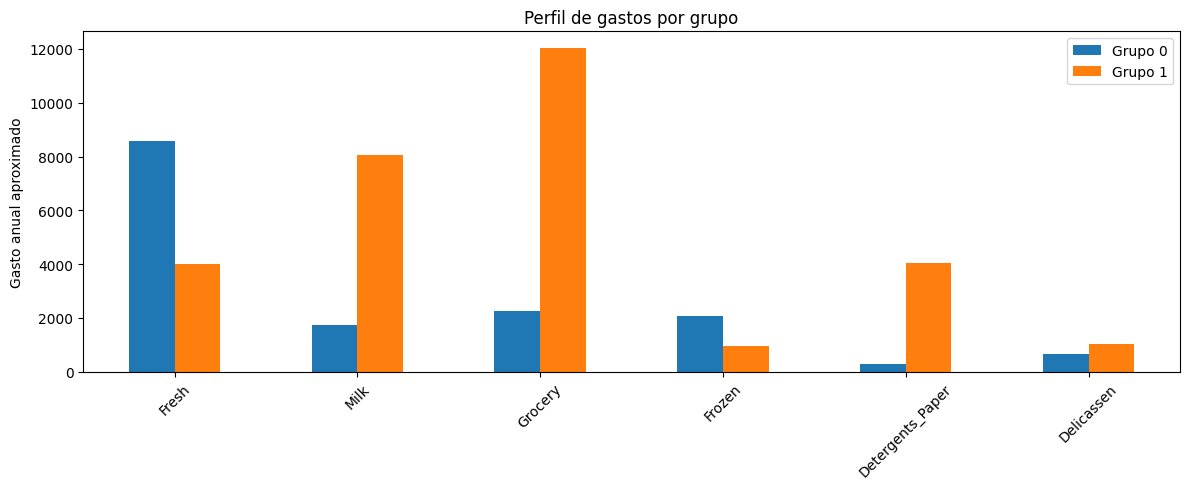

Grupo x Channel:


Channel,1,2
row_0,,
0,244,8
1,54,134


Grupo x Region:


Region,1,2,3
row_0,,,
0,48,28,176
1,29,19,140


Adjusted Rand Index com Channel: 0.5135


In [ ]:
modelo_final = KMeans(n_clusters=melhor_k, random_state=42, n_init=10)
grupos = modelo_final.fit_predict(X)

centroides_log = escalador.inverse_transform(modelo_final.cluster_centers_)
centroides_originais = np.expm1(centroides_log)
tabela_centroides = pd.DataFrame(centroides_originais, columns=gastos)
tabela_centroides.index = [f"Grupo {i}" for i in range(melhor_k)]
display(tabela_centroides.round(1))

tabela_centroides.T.plot(kind="bar", figsize=(12, 5))
plt.ylabel("Gasto anual aproximado")
plt.title("Perfil de gastos por grupo")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Grupo x Channel:")
display(pd.crosstab(grupos, channel))
print("Grupo x Region:")
display(pd.crosstab(grupos, region))
print("Adjusted Rand Index com Channel:",
      round(adjusted_rand_score(channel, grupos), 4))

## 6. Visualizar com PCA


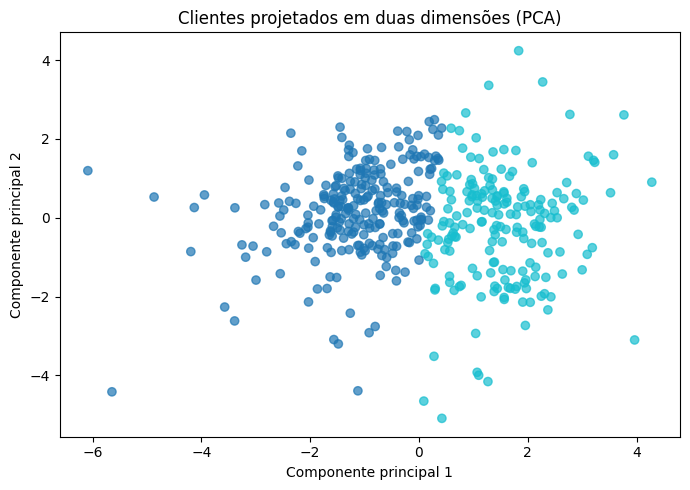

Variância explicada por cada componente: [0.44077752 0.27194917]
Variância total explicada: 0.7127266893428759


In [ ]:
pca = PCA(n_components=2, random_state=42)
pontos = pca.fit_transform(X)

plt.figure(figsize=(7, 5))
plt.scatter(pontos[:, 0], pontos[:, 1], c=grupos, alpha=0.7, cmap="tab10")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Clientes projetados em duas dimensões (PCA)")
plt.tight_layout()
plt.show()

print("Variância explicada por cada componente:", pca.explained_variance_ratio_)
print("Variância total explicada:", pca.explained_variance_ratio_.sum())